# Will this station be congested in the next 30 minutes? Comparing feature sets

The target is a yes/no question that matches the early-warning map:

> **Will this station be congested at any point in the next 30 minutes?**

- **Congested** means a measured speed below `SLOW_MPH` (40 mph). Set `CONGESTION_RULE = "occupancy"` to use each station's critical occupancy instead,
  estimated from each fold's training data.
- **The next 30 minutes** means the six 5-minute readings after the forecast time.
- **A row counts only if all six future readings were measured.** Rows where PeMS filled in any of them are left out of scoring (and out of training,
  except for the **old** set, which keeps them, as the old notebook did).

The model outputs a **probability** of congestion, which the map can show as risk. **The July–December 2025 holdout is never read.**

**Contents**
1. Load the data
2. Station order and nearest ramps
3. Features
4. The target
5. Feature sets
6. How correlated are the features?
7. Walk-forward validation (six quarterly folds)
8. Catching jams vs. false alarms, at every threshold
9. Calibration
10. What the new model relies on
11. Notes

**How it's judged**

| Measure | Meaning | Better |
|---|---|---|
| **AP, onsets** | Average precision on rows where the station is *not* congested now. This is the hard, useful case: will a jam *start*? | higher |
| **AP, all** | Average precision on every scored row (includes "already congested, will it stay congested?") | higher |
| **Brier score** | Average squared gap between the probability and what happened (0 = perfect) | lower |
| **Caught ≥15 min** | Of the congestion onsets, the share flagged at least 15 minutes ahead (probability ≥ `ALERT_THRESHOLD`) | higher |
| **False alarms / day** | Alert episodes per validation day where no congestion followed within 30 minutes | lower |
| **Wrong-alert hours / day** | Total time, summed over stations, that an alert was on and no congestion followed | lower |
| **Alerts right** | Share of alerts that were followed by congestion within 30 minutes | higher |
| **Median lead** | For flagged onsets, how early the first alert came | higher |

Average precision is the area under the precision–recall curve. It suits rare events: a model that guesses at random scores about the share of
positives, and a perfect one scores 1.

Two simple guesses are included for reference: **same as now** (congested now → predict congested) and **typical for this time**
(how often this station was congested within 30 minutes at this time of day in the training data).

In [6]:
# ---- Settings ---------------------------------------------------------------------------------------
from pathlib import Path

# Data
DATA_DIR = Path("/Users/luistorres/Documents/GitHub/fall-2026-safeflow/Data")                              # contains "D12 2023", "D12 2024", "D12 2025"
META_FILE = DATA_DIR / "d12_text_meta_2021_05_18.txt"
HOLDOUT_START = "2025-07-01"                           # files on or after this date are never read
HOUR_START, HOUR_END = 6, 19                           # keep readings from 6:00 to 19:55

# Target
WINDOW_MIN = 30                                        # "congested at any point in the next 30 minutes"
CONGESTION_RULE = "speed"                              # "speed" (speed < SLOW_MPH) or "occupancy" (>= critical occupancy)
SLOW_MPH = 40
ONSET_CLEAR_MIN = 30                                   # an onset = congested now, after at least this long uncongested

# Alerts on the map
ALERT_THRESHOLD = 0.5                                  # probability at which the map raises an alert
MIN_LEAD_MIN = 15                                      # an onset counts as "caught" if an alert came at least this early

# Validation: train on everything from TRAIN_START up to GAP_DAYS before each validation quarter
TRAIN_START = "2023-01-01"
VALIDATION_QUARTERS = [
    ("2024-01-01", "2024-04-01"),
    ("2024-04-01", "2024-07-01"),
    ("2024-07-01", "2024-10-01"),
    ("2024-10-01", "2025-01-01"),
    ("2025-01-01", "2025-04-01"),
    ("2025-04-01", "2025-07-01"),
]
GAP_DAYS = 7
ONLY_LAST_FOLD = False                                 # True = quick run on the last quarter only

# Models
TRAIN_SAMPLE = 2_000_000                               # max training rows per fit (None = use all; slower)
RUN_STEPS = True                                       # also fit the in-between feature sets
RUN_LOGISTIC = True                                    # also fit logistic regression on the new and decorrelated sets
TREE_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50,
                   early_stopping=False, random_state=0)

# Freeway-to-freeway connectors: is each one an exit from I-5 or an entrance onto it?
CONNECTOR_ROLES = {
    1208990: "exit", 1209013: "exit", 1209012: "entrance", 1210020: "exit",
    1205315: "exit", 1212015: "entrance", 1213419: "exit",
}

In [7]:
import time
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.width", 160)

KEY = ["station", "timestamp"]                         # every reading is identified by station and time
FIVE_MIN = pd.Timedelta(minutes=5)
STEPS_AHEAD = WINDOW_MIN // 5                          # number of 5-minute readings in the window (6)

# Chart style
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRAY, DARK_GRAY = "#b5b4ae", "#8f8e88"
INK, INK2, GRID, BACKGROUND = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "lines.linewidth": 2, "legend.frameon": False,
    "figure.dpi": 110,
})

## 1. Load the data
Weekdays only, without federal holidays, 6:00–19:55. Files dated on or after `HOLDOUT_START` are skipped before they are opened.

In [8]:
COLUMNS = ["timestamp", "station", "lane_type", "speed", "flow", "occupancy", "pct_observed"]
holidays = set(USFederalHolidayCalendar().holidays("2015-01-01", "2035-12-31").date)
holdout_start = pd.Timestamp(HOLDOUT_START).date()
files = sorted(DATA_DIR.rglob("d12_text_station_5min_*.parquet"))

mainline_parts, ramp_parts = [], []
days_used, holdout_files_skipped = 0, 0
start = time.time()

for i, path in enumerate(files, 1):
    day = datetime.strptime(path.stem[-10:], "%Y_%m_%d").date()
    if day >= holdout_start:
        holdout_files_skipped += 1                     # never opened
        continue
    if day.weekday() >= 5 or day in holidays:
        continue

    readings = pd.read_parquet(path, columns=COLUMNS)
    readings = readings[readings["timestamp"].dt.hour.between(HOUR_START, HOUR_END)]

    is_mainline = readings["lane_type"] == "ML"
    is_ramp = readings["lane_type"].isin(["OR", "FR"]) | readings["station"].isin(CONNECTOR_ROLES)
    mainline_parts.append(readings[is_mainline].drop(columns="lane_type"))
    ramp_parts.append(readings[is_ramp].drop(columns="lane_type"))
    days_used += 1

    if i % 100 == 0:
        print(f"read {i}/{len(files)} files ({time.time() - start:.0f}s)")


def combine(parts):
    # Stack the daily pieces, store numbers compactly, and mark which readings were measured (not filled in).
    combined = pd.concat(parts, ignore_index=True)
    for column in ["speed", "flow", "occupancy"]:
        combined[column] = combined[column].astype("float32")
    combined["real"] = combined["pct_observed"] >= 100
    return combined.drop(columns="pct_observed")


mainline = combine(mainline_parts)
ramp_readings = combine(ramp_parts)
del mainline_parts, ramp_parts
assert mainline["timestamp"].max() < pd.Timestamp(HOLDOUT_START), "holdout data was loaded"

print(f"{days_used} weekdays used out of {len(files)} files ({holdout_files_skipped} holdout files skipped, never read) | "
      f"mainline rows {len(mainline):,} | ramp rows {len(ramp_readings):,}")
measured_share = mainline.groupby(mainline["timestamp"].dt.year)["real"].mean().round(2)
print("Share of mainline readings that are measured, by year:", measured_share.to_dict())

read 100/1094 files (1s)
read 200/1094 files (1s)
read 300/1094 files (2s)
read 500/1094 files (3s)
read 600/1094 files (3s)
read 800/1094 files (4s)
read 900/1094 files (4s)
624 weekdays used out of 1094 files (182 holdout files skipped, never read) | mainline rows 4,819,328 | ramp rows 6,195,836
Share of mainline readings that are measured, by year: {2023: 0.46, 2024: 0.62, 2025: 0.64}


## 2. Station order and nearest ramps
Stations are ordered along the direction of travel. For each mainline station we record its upstream and downstream neighbor,
the nearest on-ramp at or before it, and the nearest off-ramp at or after it (several if they tie).

In [9]:
meta = pd.read_csv(META_FILE, sep="\t")
meta = meta[(meta["Fwy"] == 5) & meta["Dir"].isin(["N", "S"])].copy()
meta["Abs_PM"] = pd.to_numeric(meta["Abs_PM"], errors="coerce")
meta = meta.dropna(subset=["Abs_PM"])

# Is each detector an entrance onto the freeway or an exit from it?
meta["role"] = meta["Type"].map({"OR": "entrance", "FR": "exit"})
is_connector = meta["Type"] == "FF"
meta.loc[is_connector, "role"] = meta.loc[is_connector, "ID"].map(CONNECTOR_ROLES)

# Position along the direction of travel (postmiles decrease when heading south)
meta["travel_pm"] = np.where(meta["Dir"] == "N", meta["Abs_PM"], -meta["Abs_PM"])

stations = meta[(meta["Type"] == "ML") & meta["ID"].isin(mainline["station"].unique())]
stations = stations.sort_values(["Dir", "travel_pm"]).copy()
stations["upstream_id"] = stations.groupby("Dir")["ID"].shift(1)
stations["downstream_id"] = stations.groupby("Dir")["ID"].shift(-1)

nearest_ramps = []
for _, station in stations.iterrows():
    same_road = meta[meta["Dir"] == station["Dir"]]
    entrances_before = same_road[(same_road["role"] == "entrance") & (same_road["travel_pm"] <= station["travel_pm"])]
    exits_after = same_road[(same_road["role"] == "exit") & (same_road["travel_pm"] >= station["travel_pm"])]
    nearest_entrances = entrances_before[entrances_before["travel_pm"] == entrances_before["travel_pm"].max()]
    nearest_exits = exits_after[exits_after["travel_pm"] == exits_after["travel_pm"].min()]
    nearest_ramps.append({"station": station["ID"],
                          "on_ids": sorted(nearest_entrances["ID"]),
                          "off_ids": sorted(nearest_exits["ID"])})
nearest_ramps = pd.DataFrame(nearest_ramps)

print(f"{len(stations)} mainline stations | "
      f"stations with tied nearest on-ramps: {(nearest_ramps['on_ids'].str.len() > 1).sum()}, "
      f"tied off-ramps: {(nearest_ramps['off_ids'].str.len() > 1).sum()}")

46 mainline stations | stations with tied nearest on-ramps: 0, tied off-ramps: 8


## 3. Features
Every feature is computed at the forecast time from information available then. `df` has one row per mainline station per 5 minutes.

| Feature | Meaning |
|---|---|
| `speed`, `occupancy`, `flow` | this station's current reading |
| `speed_delta_2` | speed now − speed 10 minutes ago |
| `upstream_speed`, `downstream_speed`, `upstream_occ`, `downstream_occ` | the neighboring stations' current readings |
| `upstream_onramp_*_flow`, `downstream_offramp_*_flow` | flow on the nearest on-ramp before / off-ramp after (one column per tied ramp, as in the old notebook) |
| `onramp_flow_up`, `offramp_flow_down` | the same ramp flows, summed over tied ramps |
| `tod`, `dow`, `pm` | minutes since midnight, day of week (0 = Monday), absolute postmile |
| `down_minus_here`, `up_minus_here` | neighbor speed − this station's speed |
| `tod_sin`, `tod_cos` | time of day as a point on a 24-hour circle |

The typical-conditions features (`typical_in_30`, `typical_congestion_30`, `speed_anomaly`, `occ_anomaly`) depend on the training period,
so they're computed inside each fold (section 5 defines them).

In [10]:
df = mainline[KEY + ["speed", "occupancy", "flow", "real"]].sort_values(KEY).reset_index(drop=True)
readings_by_key = df.set_index(KEY)


def look_up(table, stations, times):
    # Rows of `table` (indexed by station and timestamp) at the given stations and times; NaN where there is no reading.
    return table.reindex(pd.MultiIndex.from_arrays([stations, times]))


def same_station_at(columns, minutes):
    # Values of `columns` at the same station, `minutes` later (negative = earlier), lined up with df's rows.
    later = df["timestamp"] + pd.Timedelta(minutes=minutes)
    return look_up(readings_by_key[columns], df["station"], later).reset_index(drop=True)


# Recent change in speed
df["speed_delta_2"] = df["speed"] - same_station_at(["speed"], -10)["speed"].to_numpy()

# Speed 30 minutes ahead, used only to build the typical-speed feature, and whether it was measured
ahead = same_station_at(["speed", "real"], WINDOW_MIN)
df["y_speed"] = ahead["speed"].to_numpy()
df["y_speed_real"] = ahead["real"].fillna(False).astype(bool).to_numpy()

# Ramp flows: one column per tied ramp (as in the old notebook), then summed
ramp_flow = ramp_readings[KEY + ["flow"]].rename(columns={"station": "ramp_id"})
OLD_RAMP_COLS = []
for list_column, prefix in [("on_ids", "upstream_onramp"), ("off_ids", "downstream_offramp")]:
    pairs = nearest_ramps[["station", list_column]].explode(list_column).dropna()
    pairs = pairs.rename(columns={list_column: "ramp_id"})
    pairs["n"] = pairs.groupby("station").cumcount() + 1
    for n in range(1, pairs["n"].max() + 1):
        column = f"{prefix}_{n}_flow"
        matched = (df[KEY]
                   .merge(pairs.loc[pairs["n"] == n, ["station", "ramp_id"]], on="station", how="left")
                   .merge(ramp_flow, on=["ramp_id", "timestamp"], how="left"))
        df[column] = matched["flow"].to_numpy()
        OLD_RAMP_COLS.append(column)

onramp_columns = [c for c in OLD_RAMP_COLS if c.startswith("upstream_onramp")]
offramp_columns = [c for c in OLD_RAMP_COLS if c.startswith("downstream_offramp")]
df["onramp_flow_up"] = df[onramp_columns].sum(axis=1, min_count=1)
df["offramp_flow_down"] = df[offramp_columns].sum(axis=1, min_count=1)

# Neighboring stations' current speed and occupancy
for id_column, side in [("upstream_id", "upstream"), ("downstream_id", "downstream")]:
    neighbor_of = stations[["ID", id_column]].rename(columns={"ID": "station", id_column: "neighbor"})
    neighbor_readings = mainline[KEY + ["speed", "occupancy"]].rename(
        columns={"station": "neighbor", "speed": f"{side}_speed", "occupancy": f"{side}_occ"})
    matched = (df[KEY]
               .merge(neighbor_of, on="station", how="left")
               .merge(neighbor_readings, on=["neighbor", "timestamp"], how="left"))
    df[f"{side}_speed"] = matched[f"{side}_speed"].to_numpy()
    df[f"{side}_occ"] = matched[f"{side}_occ"].to_numpy()

# When and where
df["tod"] = (df["timestamp"].dt.hour * 60 + df["timestamp"].dt.minute).astype("int16")
df["dow"] = df["timestamp"].dt.dayofweek.astype("int8")
df["pm"] = df["station"].map(stations.set_index("ID")["Abs_PM"]).astype("float32")

# For the decorrelated set
df["down_minus_here"] = (df["downstream_speed"] - df["speed"]).astype("float32")
df["up_minus_here"] = (df["upstream_speed"] - df["speed"]).astype("float32")
angle = 2 * np.pi * df["tod"] / (24 * 60)
df["tod_sin"] = np.sin(angle).astype("float32")
df["tod_cos"] = np.cos(angle).astype("float32")

# Bookkeeping for the folds
df["date"] = df["timestamp"].dt.normalize()
df["window_end"] = df["timestamp"] + pd.Timedelta(minutes=WINDOW_MIN)

print(f"{len(df):,} rows | memory {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

/var/folders/5j/8_72pndj63q3lxx357_lgm880000gn/T/ipykernel_35808/4250721436.py:22: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["y_speed_real"] = ahead["real"].fillna(False).astype(bool).to_numpy()


4,819,328 rows | memory 0.54 GB


## 4. The target: congestion within the next 30 minutes

`congested_now` marks each reading as congested or not. From it we build, for every forecast time:

- **`y`**: whether any of the next six readings is congested.
- **`y_known`**: whether all six of those readings were measured (only these rows are scored).
- **`y_known_any`**: whether all six exist at all, measured or filled in (the **old** set trains on these, as the old notebook did).
- **`onset`**: whether a measured congested reading comes right after `ONSET_CLEAR_MIN` minutes of measured uncongested readings.
  These are the jams a warning should catch.

With `CONGESTION_RULE = "occupancy"`, congestion depends on each station's critical occupancy, which is estimated per fold from training data.
In that case the labels are rebuilt inside each fold.

In [11]:
def critical_occupancy(train_mask):
    # Each station's occupancy (%) at which flow peaks, estimated from measured training readings.
    train = df.loc[train_mask & df["real"], ["station", "occupancy", "flow"]].dropna()
    train = train.assign(occ_bin=(train["occupancy"] * 100) // 1)          # 1-percent bins
    by_bin = train.groupby(["station", "occ_bin"])["flow"].agg(["size", lambda flow: flow.quantile(0.95)])
    by_bin.columns = ["n", "high_flow"]
    by_bin = by_bin[by_bin["n"] >= 50].reset_index()
    peak_rows = by_bin.groupby("station")["high_flow"].idxmax()
    critical = by_bin.loc[peak_rows].set_index("station")["occ_bin"] + 0.5
    return df["station"].map(critical).fillna(critical.median())


def congested_now_rule(train_mask=None):
    if CONGESTION_RULE == "speed":
        return df["speed"] < SLOW_MPH
    return df["occupancy"] * 100 >= critical_occupancy(train_mask)


def build_labels(congested_now):
    status = pd.DataFrame({"congested": congested_now.astype(float), "measured": df["real"].astype(float)})
    status.index = pd.MultiIndex.from_frame(df[KEY])

    def status_at(steps):
        # Congestion and measured flags `steps` readings later (negative = earlier) at the same station.
        found = look_up(status, df["station"], df["timestamp"] + steps * FIVE_MIN)
        return found["congested"].to_numpy(), found["measured"].to_numpy()

    # Look ahead over the next STEPS_AHEAD readings
    any_congested = np.zeros(len(df))
    all_exist = np.ones(len(df), dtype=bool)
    all_measured = np.ones(len(df), dtype=bool)
    for step in range(1, STEPS_AHEAD + 1):
        congested, measured = status_at(step)
        all_exist &= ~np.isnan(congested)
        all_measured &= measured == 1
        any_congested = np.maximum(any_congested, np.nan_to_num(congested))

    # Look back: were the previous ONSET_CLEAR_MIN minutes all measured and uncongested?
    clear_before = np.ones(len(df), dtype=bool)
    for step in range(1, ONSET_CLEAR_MIN // 5 + 1):
        congested, measured = status_at(-step)
        clear_before &= (measured == 1) & (congested == 0)

    now = congested_now.to_numpy().astype(bool)
    return pd.DataFrame({
        "congested_now": now,
        "y": any_congested.astype(bool),
        "y_known": all_exist & all_measured,
        "y_known_any": all_exist,
        "onset": now & df["real"].to_numpy() & clear_before,
    })


def set_labels(labels):
    for column in labels.columns:
        df[column] = labels[column].to_numpy()


if CONGESTION_RULE == "speed":                         # with the occupancy rule, labels are built inside each fold
    set_labels(build_labels(congested_now_rule()))
    known = df["y_known"]
    n_onsets = df["onset"].sum()
    station_days = df["date"].nunique() * df["station"].nunique()
    not_congested_now = known & ~df["congested_now"] & df["real"]
    print(f"Scored rows: {known.mean():.0%} of all rows have six measured future readings")
    print(f"Congested within 30 min: {df.loc[known, 'y'].mean():.1%} of scored rows | "
          f"onsets: {n_onsets:,} ({n_onsets / station_days:.2f} per station-day)")
    print(f"Among scored rows not congested now, {df.loc[not_congested_now, 'y'].mean():.1%} become congested within 30 min")

Scored rows: 54% of all rows have six measured future readings
Congested within 30 min: 14.6% of scored rows | onsets: 13,573 (0.47 per station-day)
Among scored rows not congested now, 4.9% become congested within 30 min


## 5. Feature sets
The **new** set adds two typical-conditions features, computed per fold from training data only: this station's average measured speed
30 minutes ahead at this time of day, and how often it was congested within 30 minutes at this time of day. For training rows, each
average leaves out that row's own day. Otherwise the feature would partly contain the answer, and the model would learn to over-trust it.

The **decorrelated** set carries the same information with no strongly correlated pair, so the team can share it across models,
including linear ones. Most features become a departure from normal, or a difference from this station:

| Feature | Definition | Replaces |
|---|---|---|
| `speed_anomaly` | speed − this station's typical speed at this time of day | `speed`, `typical_in_30` |
| `occ_anomaly` | occupancy − this station's typical occupancy at this time of day | `occupancy` |
| `typical_congestion_30` | share of training days congested within 30 min, at this station and time of day | (kept) |
| `down_minus_here`, `up_minus_here` | downstream / upstream speed − this station's speed | `downstream_speed`, `upstream_speed` |
| `tod_sin`, `tod_cos` | time of day as a point on a 24-hour circle, so a linear model can represent a daily rise and fall | `tod` |
| `speed_delta_2`, `flow`, `dow`, `pm`, `onramp_flow_up`, `offramp_flow_down` | unchanged | |

`upstream_occ` and `downstream_occ` are dropped: they mostly repeat this station's occupancy. The typical values are computed per fold,
from training days only, leaving out each training row's own day, exactly like the new set's typical features.

With `RUN_LOGISTIC = True`, both sets are also fit with **logistic regression**, the linear model for a yes/no target. Missing values are filled with
the training median plus a 0/1 "was missing" column, day of week is one-hot encoded, and every feature is standardized.

In [12]:
OLD = ["speed", "speed_delta_2"] + OLD_RAMP_COLS + ["upstream_speed", "downstream_speed"]
OCCUPANCY_AND_FLOW = ["occupancy", "flow", "upstream_occ", "downstream_occ"]
WHEN_WHERE = ["tod", "dow", "pm"]
NEW = (["speed", "speed_delta_2", "onramp_flow_up", "offramp_flow_down", "upstream_speed", "downstream_speed"]
       + OCCUPANCY_AND_FLOW + WHEN_WHERE + ["typical_in_30", "typical_congestion_30"])
DECORRELATED = ["speed_anomaly", "occ_anomaly", "typical_congestion_30", "speed_delta_2", "flow",
                "down_minus_here", "up_minus_here", "tod_sin", "tod_cos", "dow", "pm",
                "onramp_flow_up", "offramp_flow_down"]

# Each model to compare: name -> features, whether to train only on fully measured labels, and model type
MODELS = {"old": dict(features=OLD, measured_only=False, kind="trees")}
if RUN_STEPS:
    MODELS["old, trained on measured labels"] = dict(features=OLD, measured_only=True, kind="trees")
    MODELS["+ occupancy & flow"] = dict(features=OLD + OCCUPANCY_AND_FLOW, measured_only=True, kind="trees")
    MODELS["+ time, day, postmile"] = dict(features=OLD + OCCUPANCY_AND_FLOW + WHEN_WHERE, measured_only=True, kind="trees")
MODELS["new"] = dict(features=NEW, measured_only=True, kind="trees")
MODELS["decorrelated"] = dict(features=DECORRELATED, measured_only=True, kind="trees")
if RUN_LOGISTIC:
    MODELS["new, logistic regression"] = dict(features=NEW, measured_only=True, kind="logistic")
    MODELS["decorrelated, logistic regression"] = dict(features=DECORRELATED, measured_only=True, kind="logistic")

for name, spec in MODELS.items():
    model_type = "boosted trees" if spec["kind"] == "trees" else "logistic regression"
    labels_used = "measured" if spec["measured_only"] else "all"
    print(f"{name:<34} {len(spec['features']):>2} features | {model_type:<19} | trained on {labels_used} labels")

old                                 7 features | boosted trees       | trained on all labels
old, trained on measured labels     7 features | boosted trees       | trained on measured labels
+ occupancy & flow                 11 features | boosted trees       | trained on measured labels
+ time, day, postmile              14 features | boosted trees       | trained on measured labels
new                                15 features | boosted trees       | trained on measured labels
decorrelated                       13 features | boosted trees       | trained on measured labels
new, logistic regression           15 features | logistic regression | trained on measured labels
decorrelated, logistic regression  13 features | logistic regression | trained on measured labels


In [13]:
def leave_one_day_out_mean(values, usable, train_mask, keys):
    # Average of `values` over the training days, for each combination of `keys` (e.g. station and time of day).
    # Only rows that are in training AND usable count. Training rows get the average WITHOUT their own day,
    # so a row's own answer never leaks into its feature. Each key appears once per day, so "own day" = "own row".
    counted = (train_mask & usable).to_numpy()
    counted_values = np.where(counted, values.astype(float).to_numpy(), 0.0)
    groups = pd.MultiIndex.from_arrays(keys)

    def group_total(x):
        return pd.Series(x, index=groups).groupby(level=[0, 1]).sum().reindex(groups).to_numpy()

    total, count = group_total(counted_values), group_total(counted.astype(float))
    in_training = train_mask.to_numpy()
    total = np.where(in_training, total - counted_values, total)
    count = np.where(in_training, count - counted, count)
    with np.errstate(invalid="ignore", divide="ignore"):
        mean = np.where(count > 0, total / count, np.nan)
    return mean.astype("float32")


def add_typical_features(train_mask):
    # Features that depend on the training period, so they're rebuilt for every fold.
    same_time = [df["station"], df["tod"]]
    df["typical_in_30"] = leave_one_day_out_mean(df["y_speed"], df["y_speed_real"], train_mask,
                                                 [df["station"], df["tod"] + WINDOW_MIN])
    df["typical_congestion_30"] = leave_one_day_out_mean(df["y"], df["y_known"], train_mask, same_time)
    typical_speed_now = leave_one_day_out_mean(df["speed"], df["real"], train_mask, same_time)
    typical_occ_now = leave_one_day_out_mean(df["occupancy"], df["real"], train_mask, same_time)
    df["speed_anomaly"] = (df["speed"] - typical_speed_now).astype("float32")
    df["occ_anomaly"] = (df["occupancy"] - typical_occ_now).astype("float32")


def training_mask(validation_start):
    # Everything from TRAIN_START until GAP_DAYS before the validation quarter (whole 30-minute window included).
    cutoff = pd.Timestamp(validation_start) - pd.Timedelta(days=GAP_DAYS)
    return (df["timestamp"] >= TRAIN_START) & (df["window_end"] < cutoff)

## 6. How correlated are the features?
Computed on the training rows of the last fold (the largest training set). The typical-conditions features are built from those rows exactly
as they are inside the folds.

- **Pearson** correlation measures straight-line association. It's the one that matters for linear models.
- **Spearman** correlation measures any association that only goes one way (as one rises, the other rises). It's computed on a 1-million-row sample.
- **Variance inflation factor (VIF)** measures how well each feature can be predicted from *all* the others together, which catches redundancy that
  pairwise correlations miss. 1 means no overlap. Values above 5–10 are the usual warning sign for linear models.

Neither correlation captures relationships that rise and then fall. Time of day and congestion are an example: congestion peaks twice a day.

In [14]:
corr_rows = training_mask(VALIDATION_QUARTERS[-1][0])
add_typical_features(corr_rows)


def correlations(features):
    X = df.loc[corr_rows, features]
    pearson = X.corr()
    spearman = X.sample(min(len(X), 1_000_000), random_state=0).corr(method="spearman")
    return pearson, spearman


def variance_inflation(features, n=300_000):
    # VIF of feature j = 1 / (1 - R_j^2) = the j-th diagonal entry of the inverse correlation matrix (complete rows only).
    X = df.loc[corr_rows, features].dropna()
    X = X.sample(min(len(X), n), random_state=0).to_numpy(float)
    inverse = np.linalg.inv(np.corrcoef(X, rowvar=False))
    return pd.Series(np.diag(inverse), index=features)


def most_correlated_pairs(pearson, spearman, n=8):
    features = list(pearson.columns)
    pairs = [(a, b, spearman.loc[a, b], pearson.loc[a, b])
             for i, a in enumerate(features) for b in features[i + 1:]]
    table = pd.DataFrame(pairs, columns=["feature 1", "feature 2", "Spearman", "Pearson"])
    table["largest |r|"] = table[["Spearman", "Pearson"]].abs().max(axis=1)
    return table.sort_values("largest |r|", ascending=False).head(n).round(2).reset_index(drop=True)


def largest_off_diagonal(matrix):
    off_diagonal = ~np.eye(len(matrix), dtype=bool)
    return matrix.where(off_diagonal).abs().max().max()


feature_sets = {"new": NEW, "decorrelated": DECORRELATED}
corr = {name: correlations(features) for name, features in feature_sets.items()}
vif = {name: variance_inflation(features) for name, features in feature_sets.items()}

for name, (pearson, spearman) in corr.items():
    print(f"{name:<13} largest |Pearson| {largest_off_diagonal(pearson):.2f} | "
          f"largest |Spearman| {largest_off_diagonal(spearman):.2f} | largest VIF {vif[name].max():.1f}")

new           largest |Pearson| 0.89 | largest |Spearman| 0.77 | largest VIF 8.2
decorrelated  largest |Pearson| 0.62 | largest |Spearman| 0.58 | largest VIF 2.0


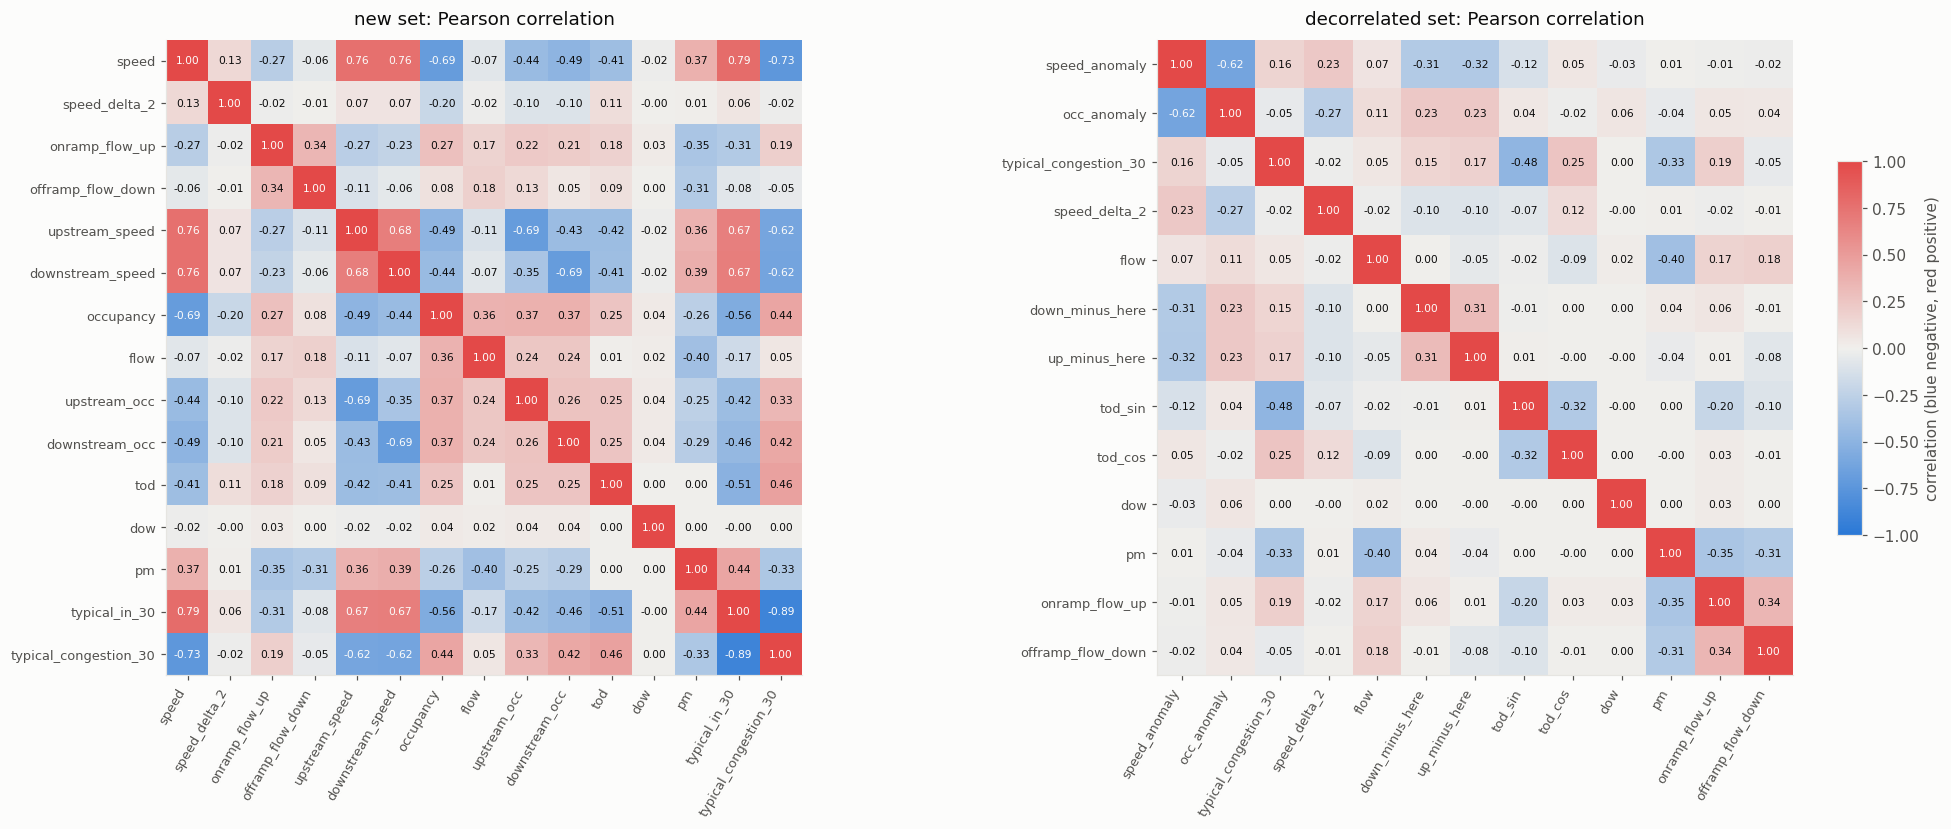

In [15]:
blue_gray_red = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, "#f0efec", "#e34948"])

fig, axes = plt.subplots(1, 2, figsize=(19, 8.5))
fig.subplots_adjust(left=0.12, right=0.9, bottom=0.2, wspace=0.55)
for ax, (name, (pearson, _)) in zip(axes, corr.items()):
    features = list(pearson.columns)
    ax.imshow(pearson.values, cmap=blue_gray_red, vmin=-1, vmax=1)
    for i in range(len(features)):
        for j in range(len(features)):
            r = pearson.values[i, j]
            text_color = BACKGROUND if abs(r) >= 0.6 else INK
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=7, color=text_color)
    ax.set_xticks(range(len(features)), features, rotation=60, ha="right", fontsize=8.5)
    ax.set_yticks(range(len(features)), features, fontsize=8.5)
    ax.grid(False)
    ax.set_title(f"{name} set: Pearson correlation", pad=10)

colorbar_axis = fig.add_axes([0.92, 0.35, 0.012, 0.4])
fig.colorbar(axes[1].images[0], cax=colorbar_axis, label="correlation (blue negative, red positive)")
plt.show()

In [16]:
print("Most correlated pairs, new set")
display(most_correlated_pairs(*corr["new"]))
print("Most correlated pairs, decorrelated set")
display(most_correlated_pairs(*corr["decorrelated"]))

vif_table = {name: values.sort_values(ascending=False).round(1).rename_axis("feature").reset_index(name="VIF")
             for name, values in vif.items()}
pd.concat(vif_table, axis=1)

Most correlated pairs, new set


,feature 1,feature 2,Spearman,Pearson,largest |r|
0,typical_in_30,typical_congestion_30,-0.76,-0.89,0.89
1,speed,typical_in_30,0.77,0.79,0.79
2,speed,upstream_speed,0.75,0.76,0.76
3,speed,downstream_speed,0.75,0.76,0.76
4,speed,typical_congestion_30,-0.60,-0.73,0.73
5,upstream_speed,upstream_occ,-0.71,-0.69,0.71
6,speed,occupancy,-0.70,-0.69,0.70
7,downstream_speed,downstream_occ,-0.70,-0.69,0.70


Most correlated pairs, decorrelated set


,feature 1,feature 2,Spearman,Pearson,largest |r|
0,speed_anomaly,occ_anomaly,-0.55,-0.62,0.62
1,typical_congestion_30,tod_sin,-0.58,-0.48,0.58
2,typical_congestion_30,pm,-0.42,-0.33,0.42
3,flow,pm,-0.39,-0.40,0.40
4,pm,onramp_flow_up,-0.36,-0.35,0.36
5,onramp_flow_up,offramp_flow_down,0.35,0.34,0.35
6,tod_sin,tod_cos,-0.33,-0.32,0.33
7,speed_anomaly,up_minus_here,-0.24,-0.32,0.32


new                decorrelated     
                  feature  VIF                feature  VIF
0           typical_in_30  8.2                     pm  2.0
1                   speed  8.1  typical_congestion_30  2.0
2   typical_congestion_30  6.2          speed_anomaly  1.8
3        downstream_speed  4.7            occ_anomaly  1.8
4          upstream_speed  4.7                tod_sin  1.6
5                      pm  2.4                   flow  1.4
6               occupancy  2.4         onramp_flow_up  1.3
7            upstream_occ  1.9      offramp_flow_down  1.3
8                    flow  1.9          up_minus_here  1.3
9          downstream_occ  1.8        down_minus_here  1.2
10                    tod  1.8          speed_delta_2  1.2
11         onramp_flow_up  1.4                tod_cos  1.1
12      offramp_flow_down  1.3                    dow  1.0
13          speed_delta_2  1.1                    NaN  NaN
14                    dow  1.0                    NaN  NaN

## 7. Walk-forward validation (six quarterly folds)
For each validation quarter: train on everything from `TRAIN_START` up to `GAP_DAYS` before the quarter, then score the quarter.
First the pieces (models and scores), then the loop.

In [17]:
def make_model(kind, features):
    if kind == "trees":
        return HistGradientBoostingClassifier(**TREE_PARAMS)
    # Logistic regression: fill gaps (plus "was missing" flags) and standardize numbers; one-hot encode day of week.
    categorical = [f for f in features if f == "dow"]
    numeric = [f for f in features if f not in categorical]
    prepare = ColumnTransformer([
        ("numeric", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), numeric),
        ("categorical", OneHotEncoder(drop="first"), categorical),
    ])
    return make_pipeline(prepare, LogisticRegression(max_iter=1000))


def fit_and_predict(spec, train_mask, val_mask):
    label_ok = df["y_known"] if spec["measured_only"] else df["y_known_any"]
    train = df[train_mask & label_ok]
    if TRAIN_SAMPLE and len(train) > TRAIN_SAMPLE:
        train = train.sample(TRAIN_SAMPLE, random_state=0)
    model = make_model(spec["kind"], spec["features"]).fit(train[spec["features"]], train["y"])
    probability = model.predict_proba(df.loc[val_mask, spec["features"]])[:, 1]
    return model, probability

In [18]:
def shifted_flags(flags, rows, minutes):
    # `flags` (a boolean Series indexed by station and timestamp) looked up `minutes` later at each row's station; False if absent.
    found = look_up(flags, rows["station"], rows["timestamp"] + pd.Timedelta(minutes=minutes))
    return found.fillna(False).astype(bool).to_numpy()


def alert_metrics(val, probability, threshold=ALERT_THRESHOLD):
    # How the map would perform if it raised an alert whenever probability >= threshold.
    # `val`: validation rows in station/time order.
    alert = pd.Series(probability >= threshold, index=pd.MultiIndex.from_frame(val[KEY]))

    # Onsets: how early before each onset did an alert come (5 to 30 minutes)? Keep the earliest.
    onsets = val[val["onset"]]
    lead_minutes = np.zeros(len(onsets))
    for step in range(1, STEPS_AHEAD + 1):
        alerted_then = shifted_flags(alert, onsets, -5 * step)
        lead_minutes = np.where(alerted_then, 5 * step, lead_minutes)
    caught = (lead_minutes >= MIN_LEAD_MIN).mean() if len(onsets) else np.nan
    median_lead = np.median(lead_minutes[lead_minutes > 0]) if (lead_minutes > 0).any() else np.nan

    # False alarms: an alert, the outcome is known, and no congestion followed within 30 minutes
    known = val["y_known"].to_numpy()
    false_alarm = pd.Series(alert.to_numpy() & known & ~val["y"].to_numpy(), index=alert.index)
    false_alarm_before = shifted_flags(false_alarm, val, -5)
    episodes = (false_alarm.to_numpy() & ~false_alarm_before).sum()     # a new episode starts after a non-false-alarm reading
    n_false = false_alarm.to_numpy().sum()
    n_known_alerts = (alert.to_numpy() & known).sum()
    days = val["date"].nunique()

    return {
        "caught ≥15 min": caught,
        "false alarms / day": episodes / days,
        "wrong-alert hours / day": n_false * 5 / 60 / days,
        "alerts right": 1 - n_false / n_known_alerts if n_known_alerts else np.nan,
        "median lead (min)": median_lead,
        "onsets": len(onsets),
    }


def score(probability, val):
    known = val["y_known"].to_numpy()
    y = val["y"].to_numpy()[known]
    p = np.asarray(probability)[known]
    not_congested_now = (~val["congested_now"].to_numpy() & val["real"].to_numpy())[known]
    ap_onsets = average_precision_score(y[not_congested_now], p[not_congested_now]) if y[not_congested_now].any() else np.nan
    return {
        "AP, onsets": ap_onsets,
        "AP, all": average_precision_score(y, p),
        "Brier": brier_score_loss(y, p),
        **alert_metrics(val, probability),
    }

In [19]:
results = []                       # one row per fold and model
val_predictions = []               # validation rows with every model's probabilities, for sections 8-9
last_new_model, last_val = None, None
quarters = VALIDATION_QUARTERS[-1:] if ONLY_LAST_FOLD else VALIDATION_QUARTERS

for fold_number, (val_start, val_end) in enumerate(quarters, 1):
    val_start, val_end = pd.Timestamp(val_start), pd.Timestamp(val_end)
    train_mask = training_mask(val_start)
    val_mask = (df["timestamp"] >= val_start) & (df["window_end"] < val_end)
    if train_mask.sum() == 0 or val_mask.sum() == 0:
        print(f"fold {fold_number}: no data, skipped")
        continue

    if CONGESTION_RULE != "speed":
        set_labels(build_labels(congested_now_rule(train_mask)))
    add_typical_features(train_mask)

    val = df[val_mask]
    fold = f"{val_start:%Y-%m} to {val_end - pd.Timedelta(days=1):%Y-%m}"
    predictions = val[KEY + ["date", "y", "y_known", "congested_now", "real", "onset"]].copy()

    baselines = {
        "same as now": val["congested_now"].astype(float).to_numpy(),
        "typical for this time": val["typical_congestion_30"].fillna(0).to_numpy(),
    }
    for name, probability in baselines.items():
        results.append({"fold": fold, "model": name, **score(probability, val)})
        predictions[name] = probability

    for name, spec in MODELS.items():
        start = time.time()
        model, probability = fit_and_predict(spec, train_mask, val_mask)
        result = {"fold": fold, "model": name, **score(probability, val)}
        results.append(result)
        predictions[name] = probability
        if name == "new":
            last_new_model, last_val = model, val
        print(f"fold {fold_number} ({fold}) | {name:<34} AP onsets {result['AP, onsets']:.3f} | "
              f"caught {result['caught ≥15 min']:.0%} | false alarms/day {result['false alarms / day']:.1f} | "
              f"{time.time() - start:.0f}s")

    val_predictions.append(predictions)

results = pd.DataFrame(results)
MODEL_ORDER = ["same as now", "typical for this time"] + list(MODELS)
METRICS = ["AP, onsets", "AP, all", "Brier", "caught ≥15 min", "false alarms / day", "wrong-alert hours / day",
           "alerts right", "median lead (min)"]
summary = results.groupby("model")[METRICS].agg(["mean", "std"]).reindex(MODEL_ORDER).round(3)
summary

/var/folders/5j/8_72pndj63q3lxx357_lgm880000gn/T/ipykernel_35808/1827873861.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()
/var/folders/5j/8_72pndj63q3lxx357_lgm880000gn/T/ipykernel_35808/1827873861.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()
/var/folders/5j/8_72pndj63q3lxx357_lgm880000gn/T/ipykernel_35808/1827873861.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future vers

fold 1 (2024-01 to 2024-03) | old                                AP onsets 0.611 | caught 37% | false alarms/day 40.0 | 11s


/var/folders/5j/8_72pndj63q3lxx357_lgm880000gn/T/ipykernel_35808/1827873861.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()


fold 1 (2024-01 to 2024-03) | old, trained on measured labels    AP onsets 0.616 | caught 39% | false alarms/day 40.6 | 7s


/var/folders/5j/8_72pndj63q3lxx357_lgm880000gn/T/ipykernel_35808/1827873861.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()


fold 1 (2024-01 to 2024-03) | + occupancy & flow                 AP onsets 0.650 | caught 47% | false alarms/day 40.8 | 8s


... (86 outputs left out)

/var/folders/5j/8_72pndj63q3lxx357_lgm880000gn/T/ipykernel_35808/1827873861.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()


fold 6 (2025-04 to 2025-06) | new, logistic regression           AP onsets 0.700 | caught 45% | false alarms/day 28.6 | 8s
fold 6 (2025-04 to 2025-06) | decorrelated, logistic regression  AP onsets 0.711 | caught 50% | false alarms/day 28.0 | 7s


/var/folders/5j/8_72pndj63q3lxx357_lgm880000gn/T/ipykernel_35808/1827873861.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()


AP, onsets        AP, all         Brier        caught ≥15 min        false alarms / day        wrong-alert hours / day  \
                                        mean    std    mean    std   mean    std           mean    std               mean    std                    mean   
model                                                                                                                                                      
same as now                            0.050  0.003   0.723  0.015  0.049  0.002          0.000  0.000             22.765  1.742                   1.897   
typical for this time                  0.563  0.039   0.894  0.016  0.040  0.004          0.541  0.064             18.067  4.883                   8.979   
old                                    0.623  0.012   0.943  0.005  0.029  0.001          0.386  0.019             36.203  2.287                   4.963   
old, trained on measured labels        0.628  0.012   0.945  0.006  0.028  0.001          0.410  0.024             37.309  2.096                   5.305   
+ occupancy & flow                     0.666  0.015   0.952  0.006  0.027  0.001          0.470  0.026             37.089  2.276                   5.275   
+ time, day, postmile                  0.746  0.012   0.963  0.004  0.023  0.001          0.626  0.032             32.188  3.651                   5.235   
new                                    0.750  0.011   0.964  0.003  0.023  0.001          0.620  0.038             31.437  3.648                   5.251   
decorrelated                           0.744  0.011   0.962  0.004  0.023  0.001          0.615  0.044             31.536  4.028                   5.402   
new, logistic regression               0.695  0.010   0.953  0.004  0.026  0.001          0.504  0.049             28.741  4.216                   5.412   
decorrelated, logistic regression      0.703  0.016   0.953  0.005  0.026  0.001          0.546  0.039             28.600  3.426                   5.498   

                                         alerts right        median lead (min)         
                                     std         mean    std              mean    std  
model                                                                                  
same as now                        0.145        0.957  0.003               NaN    NaN  
typical for this time              2.941        0.842  0.037            30.000  0.000  
old                                0.358        0.909  0.005            10.000  0.000  
old, trained on measured labels    0.281        0.904  0.008            10.833  2.041  
+ occupancy & flow                 0.344        0.905  0.008            15.000  0.000  
+ time, day, postmile              0.920        0.910  0.011            24.167  2.041  
new                                1.053        0.909  0.013            24.167  2.041  
decorrelated                       1.139        0.907  0.014            22.500  2.739  
new, logistic regression           1.273        0.904  0.018            17.500  2.739  
decorrelated, logistic regression  1.086        0.903  0.016            20.833  2.041

In [20]:
per_fold = results.pivot_table(index="fold", columns="model", values="AP, onsets").reindex(columns=MODEL_ORDER).round(3)


def compare(a, b, label):
    difference = per_fold[a] - per_fold[b]
    print(f"{label}: mean {difference.mean():+.3f}, range {difference.min():+.3f} to {difference.max():+.3f}")


print(f"AP on onsets — new beats old in {int((per_fold['new'] > per_fold['old']).sum())} of {len(per_fold)} folds")
compare("decorrelated", "new", "Decorrelated minus new (boosted trees)")
if RUN_LOGISTIC:
    compare("decorrelated, logistic regression", "new, logistic regression", "Decorrelated minus new (logistic regression)")
per_fold

AP on onsets — new beats old in 6 of 6 folds
Decorrelated minus new (boosted trees): mean -0.006, range -0.014 to +0.003
Decorrelated minus new (logistic regression): mean +0.008, range -0.003 to +0.017


model,same as now,typical for this time,old,"old, trained on measured labels",+ occupancy & flow,"+ time, day, postmile",new,decorrelated,"new, logistic regression","decorrelated, logistic regression"
fold,,,,,,,,,,
2024-01 to 2024-03,0.049,0.563,0.611,0.616,0.650,0.732,0.743,0.735,0.691,0.688
2024-04 to 2024-06,0.046,0.566,0.637,0.633,0.672,0.765,0.769,0.763,0.707,0.724
2024-07 to 2024-09,0.050,0.575,0.619,0.622,0.654,0.739,0.742,0.733,0.691,0.697
2024-10 to 2024-12,0.055,0.493,0.639,0.650,0.692,0.752,0.751,0.751,0.703,0.717
2025-01 to 2025-03,0.050,0.571,0.611,0.624,0.664,0.741,0.738,0.741,0.680,0.684
2025-04 to 2025-06,0.048,0.611,0.619,0.625,0.667,0.748,0.754,0.740,0.700,0.711


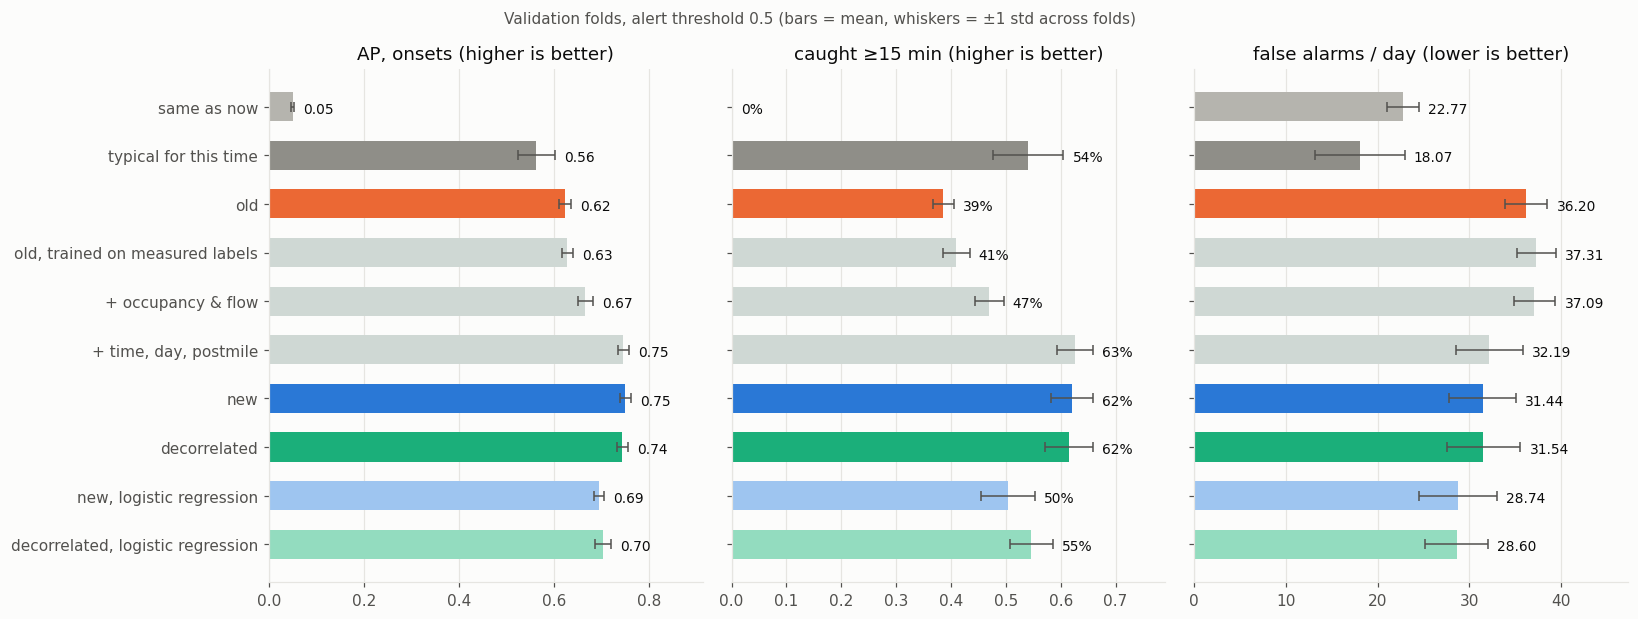

In [21]:
COLORS = {
    "same as now": GRAY, "typical for this time": DARK_GRAY, "old": ORANGE, "new": BLUE, "decorrelated": AQUA,
    "new, logistic regression": "#9ec5f0", "decorrelated, logistic regression": "#93dcbf",
}
IN_BETWEEN_COLOR = "#cfd8d4"
panels = [("AP, onsets", "higher"), ("caught ≥15 min", "higher"), ("false alarms / day", "lower")]

fig, axes = plt.subplots(1, 3, figsize=(15, 0.42 * len(MODEL_ORDER) + 1.5), sharey=True)
positions = np.arange(len(MODEL_ORDER))[::-1]
for ax, (metric, better) in zip(axes, panels):
    mean = summary[(metric, "mean")]
    spread = summary[(metric, "std")].fillna(0)
    ax.barh(positions, mean.values, xerr=spread.values, height=0.6,
            color=[COLORS.get(name, IN_BETWEEN_COLOR) for name in MODEL_ORDER],
            error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 3})
    for y, value, error in zip(positions, mean.values, spread.values):
        label = f"{value:.0%}" if metric == "caught ≥15 min" else f"{value:.2f}"
        ax.annotate(label, (value + error, y), xytext=(6, -4), textcoords="offset points", color=INK, fontsize=9)
    ax.set_xlim(0, np.nanmax((mean + spread).values) * 1.2)
    ax.set_yticks(positions, MODEL_ORDER)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{metric} ({better} is better)")

plt.suptitle(f"Validation folds, alert threshold {ALERT_THRESHOLD} (bars = mean, whiskers = ±1 std across folds)",
             color=INK2, fontsize=10)
plt.tight_layout()
plt.show()

**How to read this.** *AP, onsets* is the main number: it measures how well each model ranks the moments right before a jam starts.
*Caught* and *false alarms* depend on the alert threshold, and they trade off against each other. The next chart shows that trade-off for every threshold,
which is the fair way to compare models and pick a threshold for the map.

## 8. Catching jams vs. false alarms, at every threshold
All validation folds are pooled. Each point is one alert threshold, from 0.1 (top right) to 0.9 (bottom left). A curve further up and to the left is better.

False alarms are measured two ways, and they can disagree:
- **Left: false-alarm episodes per day.** Each unbroken stretch of wrong alerts at a station counts once, however long it lasts.
- **Right: wrong-alert hours per day.** The total time, summed over stations, that an alert was on and no congestion followed within 30 minutes.

*Typical for this time* turns on at the same hours every day, so its wrong alerts come in a few long blocks. That makes it look good on the left
and worse on the right. The model's alerts follow live conditions, so they switch on and off more often. For the map, decide which kind of
false alarm matters more. If flicker is the problem, smoothing the alert (for example, keeping it on for 15 minutes once triggered) is a cheap fix.

/var/folders/5j/8_72pndj63q3lxx357_lgm880000gn/T/ipykernel_35808/1827873861.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()
/var/folders/5j/8_72pndj63q3lxx357_lgm880000gn/T/ipykernel_35808/1827873861.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()
/var/folders/5j/8_72pndj63q3lxx357_lgm880000gn/T/ipykernel_35808/1827873861.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future vers

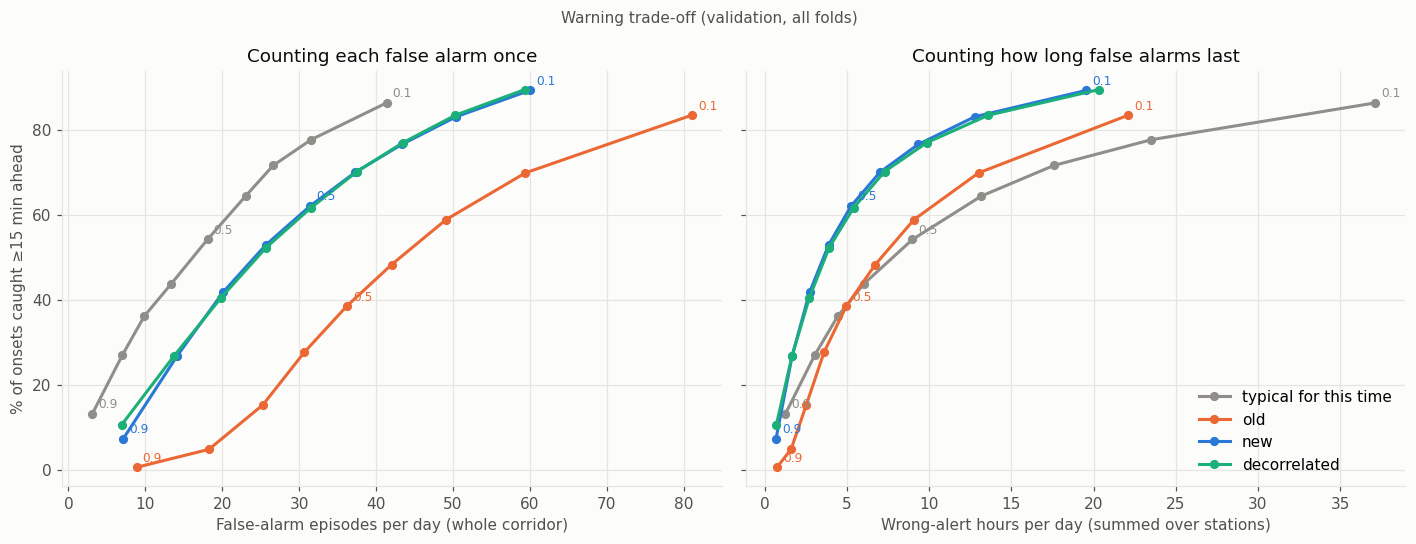

,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min),onsets
0.1,0.893,59.995,19.556,0.746,30.0,9293
0.2,0.831,50.432,12.774,0.815,30.0,9293
0.3,0.766,43.355,9.326,0.855,30.0,9293
0.4,0.700,37.299,6.996,0.885,25.0,9293
0.5,0.621,31.424,5.247,0.909,25.0,9293
0.6,0.529,25.653,3.880,0.929,20.0,9293
0.7,0.418,20.091,2.721,0.947,15.0,9293
0.8,0.269,14.155,1.667,0.965,15.0,9293
0.9,0.073,7.128,0.685,0.983,10.0,9293


In [22]:
all_val = pd.concat(val_predictions, ignore_index=True).sort_values(KEY).reset_index(drop=True)
PLOTTED = ["typical for this time", "old", "new", "decorrelated"]
thresholds = np.round(np.arange(0.1, 0.91, 0.1), 2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
tradeoff = {}
for name in PLOTTED:
    at_threshold = [alert_metrics(all_val, all_val[name].to_numpy(), threshold) for threshold in thresholds]
    tradeoff[name] = pd.DataFrame(at_threshold, index=thresholds)
    caught_percent = tradeoff[name]["caught ≥15 min"] * 100
    for ax, x_metric in zip(axes, ["false alarms / day", "wrong-alert hours / day"]):
        x = tradeoff[name][x_metric]
        ax.plot(x, caught_percent, color=COLORS[name], marker="o", markersize=5, label=name)
        if name == "decorrelated":
            continue                                   # its curve sits on top of "new"; label the thresholds once
        for threshold in (0.1, 0.5, 0.9):
            ax.annotate(f"{threshold}", (x[threshold], caught_percent[threshold]), xytext=(4, 4),
                        textcoords="offset points", color=COLORS[name], fontsize=8)

axes[0].set_xlabel("False-alarm episodes per day (whole corridor)")
axes[1].set_xlabel("Wrong-alert hours per day (summed over stations)")
axes[0].set_ylabel(f"% of onsets caught ≥{MIN_LEAD_MIN} min ahead")
axes[0].set_title("Counting each false alarm once")
axes[1].set_title("Counting how long false alarms last")
axes[1].legend(loc="lower right")
plt.suptitle("Warning trade-off (validation, all folds)", color=INK2, fontsize=10)
plt.tight_layout()
plt.show()
tradeoff["new"].round(3)

## 9. Are the probabilities honest? (calibration)
This groups predictions into bins of predicted probability and compares each bin with how often congestion actually followed.
A well-calibrated model sits on the diagonal: when it says 70%, congestion happens about 70% of the time.

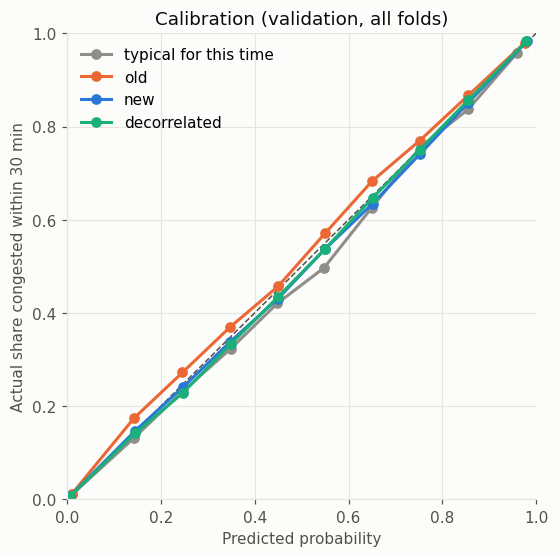

In [23]:
scored = all_val[all_val["y_known"]]
bins = np.linspace(0, 1, 11)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color=INK2, linestyle="--", linewidth=1)
for name in PLOTTED:
    by_bin = scored.groupby(pd.cut(scored[name], bins, include_lowest=True), observed=True)
    calibration = by_bin.agg(predicted=(name, "mean"), actual=("y", "mean"), n=("y", "size"))
    calibration = calibration[calibration["n"] >= 100]
    ax.plot(calibration["predicted"], calibration["actual"], color=COLORS[name], marker="o", markersize=6, label=name)

ax.set_xlabel("Predicted probability")
ax.set_ylabel("Actual share congested within 30 min")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Calibration (validation, all folds)")
ax.legend(loc="upper left")
plt.show()

## 10. What the new model relies on
Permutation importance for the new model on the last validation fold: shuffle one feature at a time and measure how much average precision drops,
on a sample of that fold's scored rows. Correlated features share credit, so each one in a correlated group looks less important than the group is.

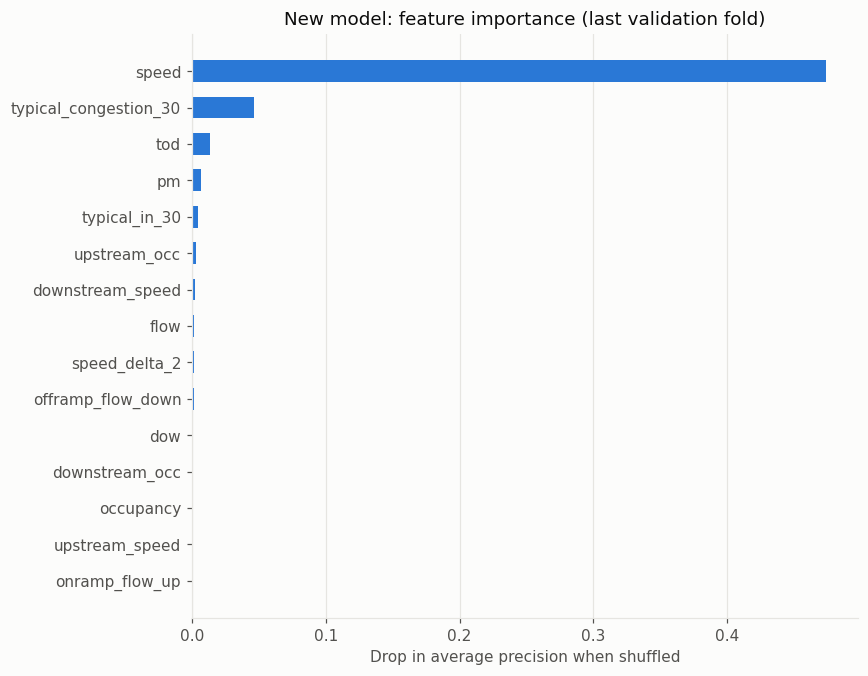

In [24]:
sample = last_val[last_val["y_known"]]
sample = sample.sample(min(len(sample), 50_000), random_state=0)
importance = permutation_importance(last_new_model, sample[NEW], sample["y"], scoring="average_precision",
                                    n_repeats=5, random_state=0)
importance = pd.Series(importance.importances_mean, index=NEW).sort_values()

fig, ax = plt.subplots(figsize=(8, 0.35 * len(NEW) + 1))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.axvline(0, color=INK2, linewidth=1)
ax.set_xlabel("Drop in average precision when shuffled")
ax.set_title("New model: feature importance (last validation fold)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 11. Notes

- **The holdout (July–December 2025) was never read.** Evaluate your final model on it once, at the end.
- **Choose the alert threshold from section 8,** by deciding how many false alarms per day the map can tolerate, not from the holdout.
- **"Typical for this time" is a strong baseline for timing alone.** It knows when jams usually start, so it often warns early. But it can't tell a normal
  day from an unusual one, which is why the model ranks onsets much better (*AP, onsets*) and wastes less alert time (section 8, right).
- **"Same as now" can't catch onsets.** It only says "congested" once a jam has started, so it catches no onsets ahead of time.
  That's why *AP, onsets* and the trade-off curve are the fair comparisons.
- **The decorrelated set is the one to share across models.** Its typical values are computed per fold, from training days only. Teammates must do
  the same: computing them once over all the data would leak the validation period into the features.
- **Low correlation mainly matters for reading a linear model's coefficients,** since it keeps them stable. It isn't what makes a linear model
  predict well, so expect logistic regression to stay behind the boosted trees whichever set it uses.
- **Rows with filled-in future readings are never scored.** If too few rows remain at some stations, consider requiring only 5 of 6 measured readings.
- **Next ideas.** Occupancy relative to critical occupancy as a feature; distance to the nearest congested station downstream; separate models for
  the morning and evening peaks.